# Exit status and conditional execution

Observe matching, nonmatching and missing input through grep exit codes.

A nonmatch is an expected outcome in a search. A missing file is an operational error. Test the distinction explicitly. Commands in if conditions can be inspected without treating every nonzero return as a fatal shell error.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
printf '%s\n' 'tea' 'coffee' > drinks
for pattern in tea water; do
    if grep -q "$pattern" drinks; then printf '0\n'; else printf '%s\n' "$?"; fi
done
if grep -q tea absent 2>/dev/null; then printf '0\n'; else printf '%s\n' "$?"; fi
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [0, 1, 2]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers[:2] == [0, 1] and numbers[2] > 1
observed = runs[shells[0]]

sh [0, 1, 2]
bash [0, 1, 2]
zsh [0, 1, 2]


## Inspect the outcome

The POSIX guarantee for an error is a status greater than one. GNU and BSD grep normally return two here. The verification accepts any error status above one.

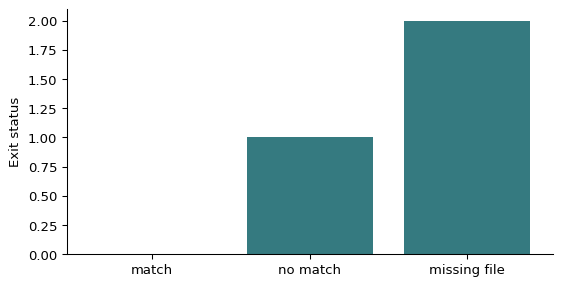

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["match", "no match", "missing file"], observed, color="#357a80")
ax.set(ylabel="Exit status")
plt.show()

## Interpreting the result

The POSIX guarantee for an error is a status greater than one. GNU and BSD grep normally return two here. The verification accepts any error status above one.

## Exercise

Use a conditional branch to report a nonmatch without hiding a genuine input error.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)